# Assignment 4: Cats and Dogs Classification
**Hazem Daw | Group J4132**  
Machine Learning Technologies, ITMO University, 2026

The task is to classify photographs as cats or dogs. The experiments compare a three-layer CNN trained from scratch with two transfer-learning models. A separate residual CNN is trained without pretrained weights for the optional contest.

| Section | Experiment |
|---|---|
| [Part 1](#part1) | Three-layer CNN |
| [Part 2](#part2) | VGG16 and ResNet18 transfer learning |
| [Part 3](#part3) | Residual CNN trained from scratch |
| [Evaluation](#evaluation) | Test metrics, learning curves and errors |
| [Custom image](#custom) | Inference with the validation-selected model |

### Running the notebook
The saved outputs show the completed experiments described below. Open the notebook to read them without running any cells. All implementation code is included here.

**Run All repeats data preparation, training and evaluation**, including the 60-epoch optional experiment. It downloads the course data and the Part 2 pretrained weights as needed, and writes generated files to `task4_runtime/`. A GPU is recommended. To use a different photograph, set `CUSTOM_IMAGE_PATH` in the setup cell.

The submitted experiments used Python 3.11, PyTorch 2.11.0, torchvision 0.26.0 and an NVIDIA RTX 3060. The numerical discussion and embedded example panels refer to those runs; retraining can produce different results.

If needed, install dependencies before running:
```python
%pip install torch==2.11.0 torchvision==0.26.0 numpy pandas matplotlib Pillow scikit-learn gdown "pyzmq>=27,<28"
```
Restart the kernel after installation. On Windows, pyzmq 27 or later avoids the runtime DLL conflict observed with an older installation.


In [ ]:
from pathlib import Path
import os, csv, json, math, random, time, hashlib, shutil, zipfile, contextlib
from concurrent.futures import ThreadPoolExecutor
import urllib.request
import torch  # Import before plotting extensions on Windows.
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
import torchvision
from torchvision import datasets, transforms, models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, confusion_matrix, classification_report

CUSTOM_IMAGE_PATH = None  # e.g. '/content/my_dog.jpg'; None uses the demonstrated dog image.
ROOT = Path.cwd() / 'task4_runtime'  # Generated data, checkpoints and results.
WORKERS = 0 if os.name == 'nt' else 2  # Notebook-safe: Windows cannot spawn notebook-defined workers.
os.environ.setdefault('TORCH_HOME', str(ROOT / '.cache' / 'torch'))
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
FILE_ID = '1lPLlLKhRXvtCG4SNXYflIiy09DMqqPkN'
ARCHIVE_SHA256 = '540915915226479357a1e738bd920c3e19e5a3d8fc56c0622dffa5d682e3631c'
get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.18})
print('PyTorch:', torch.__version__, '| GPU available:', torch.cuda.is_available())

PyTorch: 2.11.0+cu128 | GPU available: True


## Data preparation
The supplied archive contains 24,990 readable images: 20,000 for training, 2,490 for validation and 2,500 for testing. The validation split has 1,240 cats and 1,250 dogs. Both test classes contain 1,250 images, giving a constant-class baseline of 50% accuracy.

File hashes and decoded RGB-pixel hashes were checked for duplicates. Three duplicate groups cross split boundaries and two occur within training. Five redundant training copies were excluded, leaving **19,995 training images**. The supplied validation and test images were retained. Two test dog photographs are identical, so the accuracy intervals should be interpreted as approximate.

`ImageFolder` assigns **cats = 0** and **dogs = 1**. The validation set is used to select checkpoints and inference settings. The test set is used after these choices have been fixed.

In [ ]:
def prepare(root):
    root = Path(root).resolve()
    root.mkdir(parents=True, exist_ok=True)
    destination = root / 'Cats_and_Dogs'
    marker = root / 'extraction.json'
    if marker.exists():
        metadata = json.loads(marker.read_text())
        images = [p for p in destination.rglob('*') if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}]
        if len(images) == metadata['images']:
            return destination
        raise ValueError('Extracted dataset is incomplete. Restore the original archive before continuing.')
    archive = root / 'Cats_and_Dogs.zip'
    if not archive.exists():
        import gdown
        gdown.download(id=FILE_ID, output=str(archive), quiet=False)
    if not zipfile.is_zipfile(archive):
        raise ValueError('Download is not a complete ZIP archive.')
    archive_digest = hashlib.sha256(archive.read_bytes()).hexdigest()
    if archive_digest != ARCHIVE_SHA256:
        raise ValueError('Course archive differs from the recorded experiment; check its source/version.')
    with zipfile.ZipFile(archive) as zf:
        for member in zf.infolist():
            parts = Path(member.filename).parts
            if 'Cats_and_Dogs' not in parts or '__MACOSX' in parts:
                continue
            parts = parts[parts.index('Cats_and_Dogs') + 1:]
            if not parts or member.is_dir() or parts[-1].startswith('.'):
                continue
            target = destination.joinpath(*parts).resolve()
            if not target.is_relative_to(destination.resolve()):
                raise ValueError('Unsafe ZIP path')
            target.parent.mkdir(parents=True, exist_ok=True)
            if not target.exists() or target.stat().st_size != member.file_size:
                with zf.open(member) as source, target.open('wb') as out:
                    shutil.copyfileobj(source, out)
    marker.write_text(json.dumps(dict(images=len(list(destination.rglob('*.jpg'))),
                                      archive_sha256=archive_digest), indent=2))
    return destination


def audit(data_root, out_dir):
    data_root, out_dir = Path(data_root), Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    paths = sorted(p for p in data_root.rglob('*') if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})

    def inspect(path):
        parts = path.relative_to(data_root).parts
        with Image.open(path) as im:
            rgb = im.convert('RGB')
            rgb.load()
            width, height = rgb.size
            pixels = hashlib.sha256(f'{width}x{height}'.encode() + rgb.tobytes()).hexdigest()
        return dict(path=path.relative_to(data_root).as_posix(), split=parts[0],
                    label=parts[1], width=width, height=height,
                    sha256=hashlib.sha256(path.read_bytes()).hexdigest(), pixel_sha256=pixels)

    with ThreadPoolExecutor(max_workers=8) as pool:
        rows = list(pool.map(inspect, paths))
    with (out_dir / 'data_manifest.csv').open('w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    counts, hashes = {}, {}
    for row in rows:
        key = f"{row['split']}/{row['label']}"
        counts[key] = counts.get(key, 0) + 1
        hashes.setdefault(row['pixel_sha256'], []).append(row['path'])
    duplicates = [v for v in hashes.values() if len(v) > 1]
    cross = [v for v in duplicates if len({p.split('/')[0] for p in v}) > 1]
    summary = dict(total=len(rows), counts=counts, unreadable_images=0,
                   duplicate_groups=duplicates, cross_split_duplicates=cross,
                   source=f'https://drive.google.com/file/d/{FILE_ID}/view')
    (out_dir / 'data_audit.json').write_text(json.dumps(summary, indent=2))
    print(json.dumps(summary, indent=2), flush=True)
    return summary

In [ ]:
data_root = prepare(ROOT / 'data')
data_audit = audit(data_root, ROOT / 'results')
display(pd.Series(data_audit['counts'], name='Original image count').to_frame())
print('Unreadable images:', data_audit['unreadable_images'])
print('Cross-split duplicate groups:', len(data_audit['cross_split_duplicates']))
excluded = set()
for group in data_audit['duplicate_groups']:
    training = sorted(p for p in group if p.startswith('train/'))
    has_evaluation = any(not p.startswith('train/') for p in group)
    excluded.update(training if has_evaluation else training[1:])
train_count = sum(n for split, n in data_audit['counts'].items() if split.startswith('train/'))
print('Training images after duplicate removal:', train_count - len(excluded))

,Original image count
test/cats,1250
test/dogs,1250
train/cats,10000
train/dogs,10000
val/cats,1240
val/dogs,1250


Unreadable images: 0
Cross-split duplicate groups: 3
Training images after duplicate removal: 19995


### Training examples

Examples from the training split.

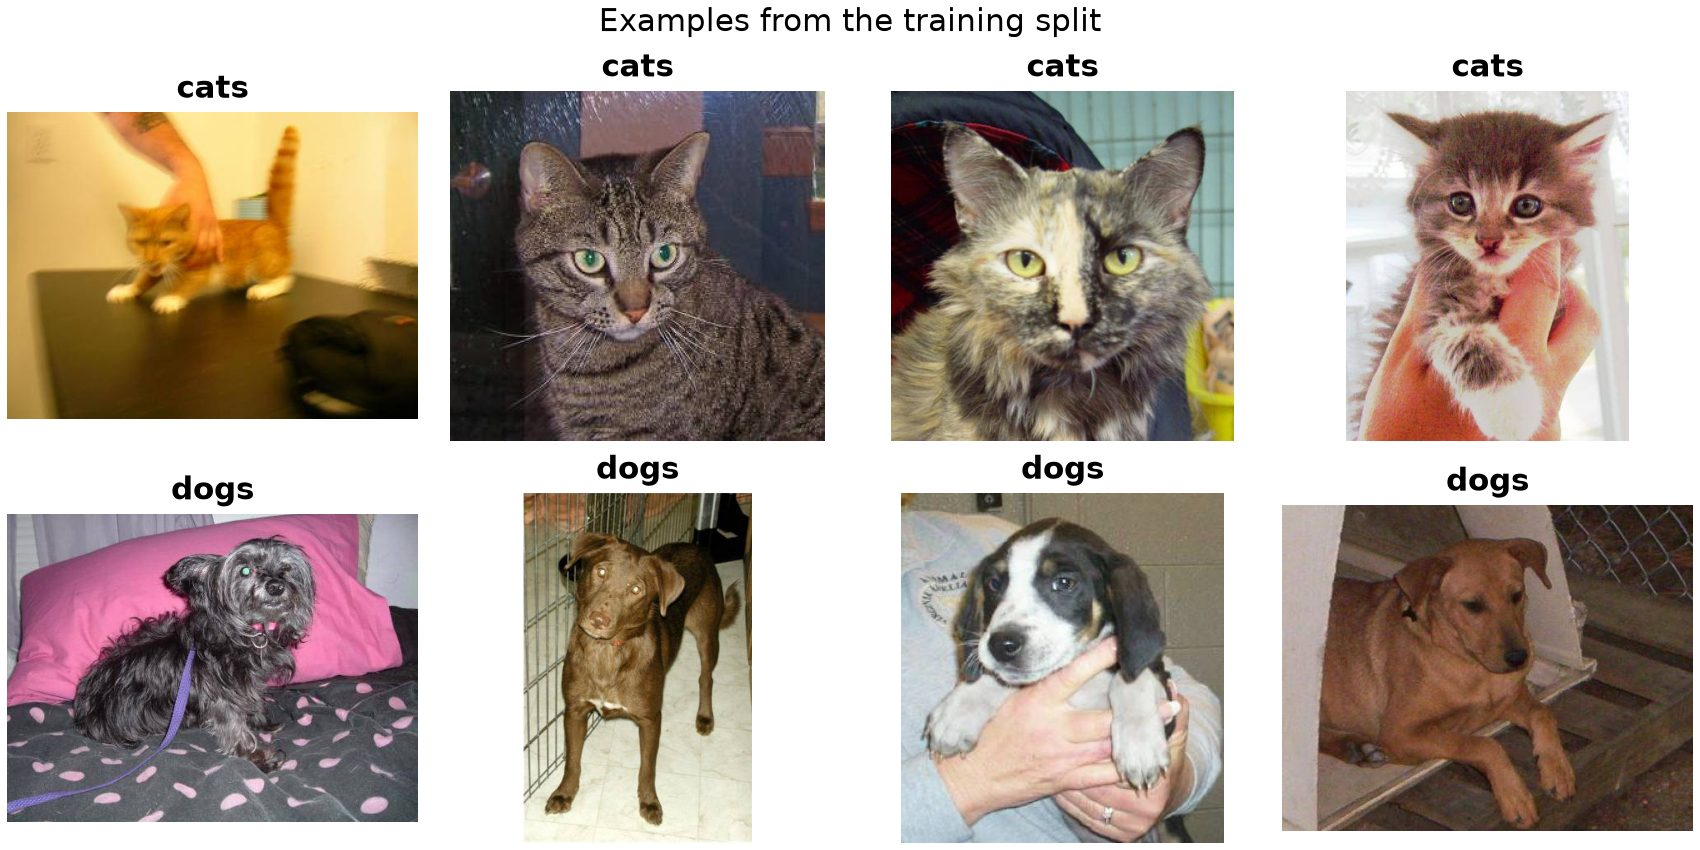

In [ ]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.set_num_threads(4)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def seed_worker(_):
    seed = torch.initial_seed() % 2**32
    np.random.seed(seed)
    random.seed(seed)
    torch.set_num_threads(1)


def preprocessing(name, training=False, size=128):
    if name == 'cnn':
        return transforms.Compose([transforms.Resize((150, 150)), transforms.ToTensor()])
    if name in ('vgg16', 'resnet18'):
        weights = models.VGG16_Weights.IMAGENET1K_V1 if name == 'vgg16' else models.ResNet18_Weights.IMAGENET1K_V1
        return weights.transforms()
    if training:
        return transforms.Compose([
            transforms.RandomResizedCrop(size, scale=(0.65, 1.0), ratio=(0.8, 1.25)),
            transforms.RandomHorizontalFlip(), transforms.ColorJitter(0.15, 0.15, 0.15, 0.03),
            transforms.ToTensor(), transforms.Normalize((0.5,) * 3, (0.5,) * 3)])
    return transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor(),
                                transforms.Normalize((0.5,) * 3, (0.5,) * 3)])


def loader(dataset, batch_size=64, shuffle=False, workers=4, seed=42):
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=workers,
                      pin_memory=torch.cuda.is_available(), persistent_workers=workers > 0,
                      worker_init_fn=seed_worker, generator=torch.Generator().manual_seed(seed))


def remove_training_duplicates(dataset, data_root):
    audit_path = ROOT / 'results/data_audit.json'
    if not audit_path.exists():
        raise FileNotFoundError('Run the data preparation cells before training; the duplicate audit is required.')
    audit = json.loads(audit_path.read_text())
    excluded = set()
    for group in audit['duplicate_groups']:
        training = sorted(p for p in group if p.startswith('train/'))
        has_evaluation = any(not p.startswith('train/') for p in group)
        excluded.update(training if has_evaluation else training[1:])
    dataset.samples = [(p, y) for p, y in dataset.samples
                       if Path(p).relative_to(data_root).as_posix() not in excluded]
    dataset.imgs = dataset.samples
    dataset.targets = [y for _, y in dataset.samples]
    return sorted(excluded)


def amp(device):
    return torch.autocast(device_type='cuda', dtype=torch.float16) if device.type == 'cuda' else contextlib.nullcontext()


@torch.inference_mode()
def evaluate(model, batches, device, tta=False):
    model.eval()
    ys, logits = [], []
    for x, y in batches:
        x = x.to(device, non_blocking=True).float()
        with amp(device):
            z = model(x)
            if tta:
                z = (z + model(x.flip(-1))) / 2
        logits.append(z.float().cpu())
        ys.append(y.cpu())
    y, z = torch.cat(ys).float(), torch.cat(logits)
    return dict(loss=nn.functional.binary_cross_entropy_with_logits(z, y).item(),
                accuracy=((z >= 0) == y.bool()).float().mean().item(),
                y=y.numpy(), probabilities=z.sigmoid().numpy())


def extract_features(model, dataset, name, split, device, workers, batch_size):
    cache = ROOT / '.cache' / f'{name}_{split}'
    cache.parent.mkdir(exist_ok=True, parents=True)
    # Cache is tied to exact image bytes/order and preprocessing implementation.
    signature = hashlib.sha256(f"standalone-v1|{name}|IMAGENET1K_V1|resize256-crop224|{torchvision.__version__}".encode())
    for path, label in dataset.samples:
        signature.update(Path(path).read_bytes())
        signature.update(str(label).encode())
    digest = signature.hexdigest()
    marker = cache.with_suffix('.json')
    if marker.exists() and json.loads(marker.read_text())['sha256'] == digest:
        return np.load(cache.with_suffix('.npy'), mmap_mode='r')
    batches = loader(dataset, batch_size=batch_size, workers=workers)
    model.eval()
    features, offset = None, 0
    with torch.inference_mode():
        for x, _ in batches:
            with amp(device):
                f = model.features(x.to(device)).cpu().numpy().astype(np.float16)
            if features is None:
                features = np.lib.format.open_memmap(cache.with_suffix('.npy'), mode='w+',
                                                     dtype='float16', shape=(len(dataset), f.shape[1]))
            features[offset:offset + len(f)] = f
            offset += len(f)
            if offset % (batch_size * 50) == 0:
                print(f'{name}: extracted {split} {offset}/{len(dataset)}', flush=True)
    features.flush()
    marker.write_text(json.dumps(dict(sha256=digest, count=offset)))
    return np.load(cache.with_suffix('.npy'), mmap_mode='r')


class FeatureDataset(Dataset):
    def __init__(self, features, targets):
        self.features, self.targets = features, targets

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, index):
        return torch.from_numpy(self.features[index].astype(np.float32)), self.targets[index]


class HeadWrapper(nn.Module):
    def __init__(self, head):
        super().__init__()
        self.head = head

    def forward(self, x):
        return self.head(x).squeeze(1)


def train_run(name, epochs, seed=42, size=128, batch_size=64, workers=4, lr=None,
              data_root=None, run_name=None):
    seed_everything(seed)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    data_root = Path(data_root or ROOT / 'data' / 'Cats_and_Dogs')
    run_name = run_name or name
    output = ROOT / 'results' / run_name
    output.mkdir(parents=True, exist_ok=True)
    checkpoint_dir = ROOT / 'checkpoints'
    checkpoint_dir.mkdir(exist_ok=True)
    train_ds = datasets.ImageFolder(data_root / 'train', preprocessing(name, True, size))
    excluded = remove_training_duplicates(train_ds, data_root)
    val_ds = datasets.ImageFolder(data_root / 'val', preprocessing(name, False, size))
    assert train_ds.class_to_idx == val_ds.class_to_idx
    assert list(train_ds.class_to_idx.values()) == [0, 1]
    pretrained = name in ('vgg16', 'resnet18')
    model = build_model(name, pretrained=pretrained).to(device)
    actual_size = 150 if name == 'cnn' else 224 if pretrained else size
    config = dict(name=name, run_name=run_name, epochs=epochs, seed=seed, image_size=actual_size,
                  batch_size=batch_size, class_to_idx=train_ds.class_to_idx,
                  pretrained=pretrained, train_images=len(train_ds), validation_images=len(val_ds),
                  excluded_training_duplicates=excluded,
                  device=str(device), gpu=torch.cuda.get_device_name(0) if device.type == 'cuda' else None,
                  torch=str(torch.__version__), selection='minimum validation BCE, threshold fixed at 0.5',
                  parameters=sum(p.numel() for p in model.parameters()),
                  trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad))
    if pretrained:
        train_f = extract_features(model, train_ds, name, 'train', device, workers, batch_size)
        val_f = extract_features(model, val_ds, name, 'val', device, workers, batch_size)
        train_batches = loader(FeatureDataset(train_f, train_ds.targets), batch_size=256, shuffle=True, workers=0, seed=seed)
        val_batches = loader(FeatureDataset(val_f, val_ds.targets), batch_size=256, workers=0)
        fit_model = HeadWrapper(model.head)
    else:
        train_batches = loader(train_ds, batch_size, True, workers, seed)
        val_batches = loader(val_ds, batch_size, False, workers, seed)
        fit_model = model
    lr = lr or {'cnn': 0.001, 'vgg16': 0.0001, 'resnet18': 0.001, 'scratch': 0.002}[name]
    config['lr'] = lr
    config['weight_decay'] = 0.0001 if name == 'scratch' else 0.0
    config['augmentation'] = 'random crop, horizontal flip, color jitter; 0.05 label smoothing' if name == 'scratch' else 'none'
    optimizer = torch.optim.AdamW((p for p in fit_model.parameters() if p.requires_grad), lr=lr,
                                   weight_decay=config['weight_decay'])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=lr * 0.01) if name == 'scratch' else None
    scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')
    best, history, started = math.inf, [], time.perf_counter()
    (output / 'config.json').write_text(json.dumps(config, indent=2))
    print(json.dumps(config), flush=True)
    for epoch in range(1, epochs + 1):
        tic = time.perf_counter()
        fit_model.train()
        total_loss, correct, total = 0.0, 0, 0
        epoch_lr = optimizer.param_groups[0]['lr']
        for x, y in train_batches:
            x, y = x.to(device, non_blocking=True).float(), y.to(device, non_blocking=True).float()
            optimizer.zero_grad(set_to_none=True)
            targets = y * 0.95 + 0.025 if name == 'scratch' else y
            with amp(device):
                z = fit_model(x)
                loss = nn.functional.binary_cross_entropy_with_logits(z, targets)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(fit_model.parameters(), 5.0)
            scaler.step(optimizer)
            scaler.update()
            total_loss += loss.item() * len(y)
            correct += ((z >= 0) == y.bool()).sum().item()
            total += len(y)
        val = evaluate(fit_model, val_batches, device)
        row = dict(epoch=epoch, train_loss=total_loss / total, train_accuracy=correct / total,
                   val_loss=val['loss'], val_accuracy=val['accuracy'], learning_rate=epoch_lr,
                   seconds=time.perf_counter() - tic)
        history.append(row)
        if val['loss'] < best:
            best = val['loss']
            torch.save(dict(state_dict=model.state_dict(), config=config, best_epoch=epoch,
                            validation_loss=best, validation_accuracy=val['accuracy']),
                       checkpoint_dir / f'{run_name}.pt')
        with (output / 'history.csv').open('w', newline='') as f:
            writer = csv.DictWriter(f, fieldnames=list(row))
            writer.writeheader()
            writer.writerows(history)
        print(f"{run_name} {epoch}/{epochs}: train {row['train_accuracy']:.4f}, val {row['val_accuracy']:.4f}, val BCE {val['loss']:.4f}, {row['seconds']:.1f}s", flush=True)
        if scheduler:
            scheduler.step()
    config['training_seconds'] = time.perf_counter() - started
    (output / 'config.json').write_text(json.dumps(config, indent=2))
    return history

In [ ]:
def build_model(name, pretrained=False):
    if name == 'cnn':
        return CNNModel()
    if name == 'scratch':
        return ScratchResNet()
    return TransferModel(name, pretrained=pretrained)

### Training and validation
All models return logits and use `BCEWithLogitsLoss`. Sigmoid is applied only to obtain probabilities. The prediction threshold is fixed at 0.5.

The checkpoint with minimum validation BCE is retained. Training metrics are collected with dropout active and, for the contest model, augmented images. Validation uses evaluation mode and no random augmentation.

Notebook data loaders use zero workers on Windows because notebook-defined functions cannot be spawned as worker processes. The recorded training runs used four workers. Fixed seeds improve reproducibility, but hardware, worker count and library versions can change numerical results.

In [ ]:
NAMES = {'cnn': 'Three-layer CNN', 'vgg16': 'VGG16 transfer',
         'resnet18': 'ResNet18 transfer', 'scratch': 'Residual CNN from scratch'}

def show_history(history, name):
    history = pd.DataFrame(history)
    best_epoch = int(history.loc[history.val_loss.idxmin(), 'epoch'])
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout='constrained')
    for ax, metric, label in zip(axes, ['loss', 'accuracy'], ['Binary cross-entropy', 'Accuracy']):
        ax.plot(history.epoch, history['train_' + metric], label='Training', color='#176B87', lw=2)
        ax.plot(history.epoch, history['val_' + metric], label='Validation', color='#E17C37', lw=2)
        ax.axvline(best_epoch, color='#777777', ls=':', label=f'Selected epoch {best_epoch}')
        ax.set(xlabel='Epoch', ylabel=label, title=label)
        ax.legend(fontsize=8)
    fig.suptitle(NAMES[name])
    plt.show()
    plt.close(fig)
    print(f'{name}: {len(history)} epochs; selected checkpoint = epoch {best_epoch}')
    display(history.tail(3).round(5))

<a id="part1"></a>
## Part 1: Three-layer CNN
The baseline follows the supplied architecture: three 3×3 convolutions with 16, 32 and 64 output channels, each followed by ReLU and 2×2 max pooling. With 150×150 input, the pooled spatial sizes are 75, 37 and 18. The final feature map is flattened to 20,736 values and passed through a 64-unit layer, ReLU, dropout 0.5 and one output logit.

Pixels are scaled to [0,1]. The model is trained for 15 epochs using batch size 128, learning rate 0.001 and seed 42. AdamW is used with zero weight decay. There is no sigmoid layer because it is included in the loss function.

In [ ]:
class CNNModel(nn.Module):
    """The exact three-convolution, 150 x 150 course baseline."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(64 * 18 * 18, 64),
                                  nn.ReLU(), nn.Dropout(0.5), nn.Linear(64, 1))

    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)

Parameters:

 1350817
Output shape: (2,)


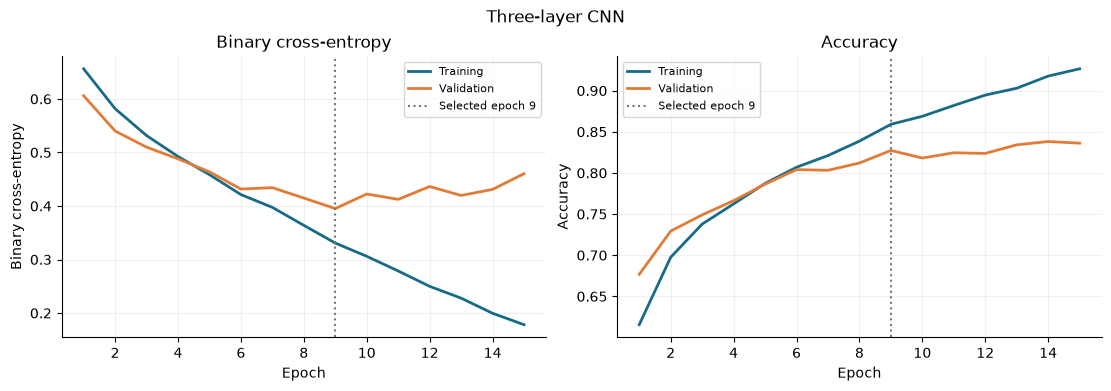

cnn: 15 epochs; selected checkpoint = epoch 9


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,seconds
12,13,0.22782,0.90293,0.41966,0.83414,0.001,9.97301
13,14,0.19954,0.91768,0.43100,0.83815,0.001,10.13380
14,15,0.17819,0.92653,0.46035,0.83614,0.001,10.65686


In [ ]:
baseline = CNNModel()
print('Parameters:', sum(p.numel() for p in baseline.parameters()))
print('Output shape:', tuple(baseline(torch.zeros(2, 3, 150, 150)).shape))
del baseline
cnn_history = train_run('cnn', epochs=15, batch_size=128, workers=WORKERS)
show_history(cnn_history, 'cnn')

The selected baseline checkpoint is epoch 9. It correctly classifies **2,054 of 2,500 test images (82.16%)**. Training accuracy continues to improve in later epochs, while validation BCE increases. This supports selecting a checkpoint from validation performance instead of using the final epoch.

Numerical values in the discussion describe the submitted run. A new training run produces its own final results table.

<a id="part2"></a>
## Part 2: Transfer learning
VGG16 and ResNet18 use torchvision's `IMAGENET1K_V1` weights. Each model uses its weight-specific preprocessing: resize the shorter image edge to 256, center crop to 224, convert to a tensor and normalize with ImageNet mean and standard deviation.

The VGG16 classifier is replaced with a 25,088 → 256 → 1 head. ResNet18 uses a 512 → 256 → 1 head. Both heads have ReLU and dropout 0.5. Backbone parameters are frozen; keeping the backbone in evaluation mode also freezes ResNet's BatchNorm running statistics.

The deterministic frozen features are cached once in float16 and converted to float32 for head training. This avoids repeated backbone passes, with a small rounding approximation. Both models train their new heads for 15 epochs; the learning rates are 0.0001 for VGG16 and 0.001 for ResNet18.

In [ ]:
class TransferModel(nn.Module):
    def __init__(self, architecture, pretrained=True):
        super().__init__()
        if architecture == 'vgg16':
            net = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1 if pretrained else None)
            self.features = nn.Sequential(net.features, nn.AdaptiveAvgPool2d((7, 7)), nn.Flatten())
            self.head = nn.Sequential(nn.Linear(512 * 7 * 7, 256), nn.ReLU(),
                                      nn.Dropout(0.5), nn.Linear(256, 1))
        elif architecture == 'resnet18':
            net = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
            self.features = nn.Sequential(*list(net.children())[:-1], nn.Flatten())
            self.head = nn.Sequential(nn.Linear(512, 256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, 1))
        else:
            raise ValueError(architecture)
        self.features.requires_grad_(False)

    def train(self, mode=True):
        super().train(mode)
        # Freezing parameters alone does not freeze ResNet's BatchNorm statistics.
        self.features.eval()
        return self

    def forward(self, x):
        with torch.no_grad():
            features = self.features(x)
        return self.head(features).squeeze(1)

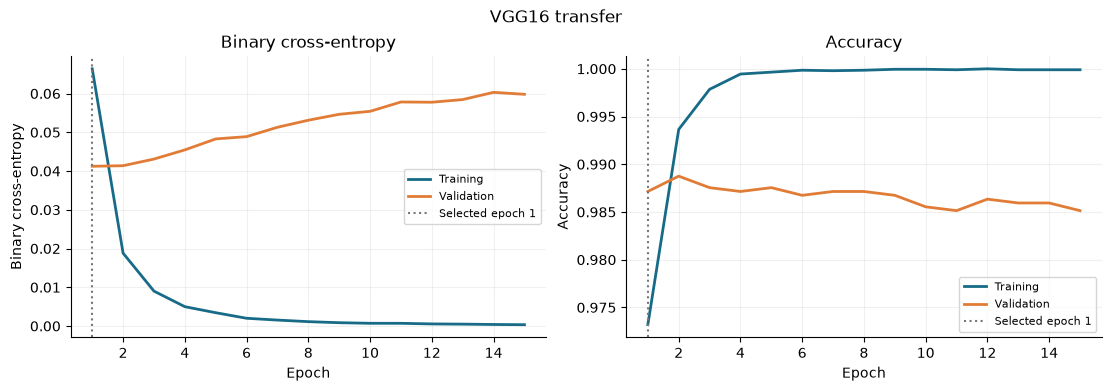

vgg16: 15 epochs; selected checkpoint = epoch 1


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,seconds
12,13,0.00049,0.9999,0.05844,0.98594,0.0001,2.19890
13,14,0.00040,0.9999,0.06031,0.98594,0.0001,2.10032
14,15,0.00034,0.9999,0.05980,0.98514,0.0001,2.30166


In [ ]:
# VGG16: train the new head for 15 epochs, learning rate 0.0001.
vgg16_history = train_run('vgg16', epochs=15, batch_size=64, workers=WORKERS)
show_history(vgg16_history, 'vgg16')

VGG16 correctly classifies **2,458 of 2,500 test images (98.32%)**. The minimum validation BCE occurs at epoch 1. Later epochs fit the training features more closely without improving validation probability estimates.

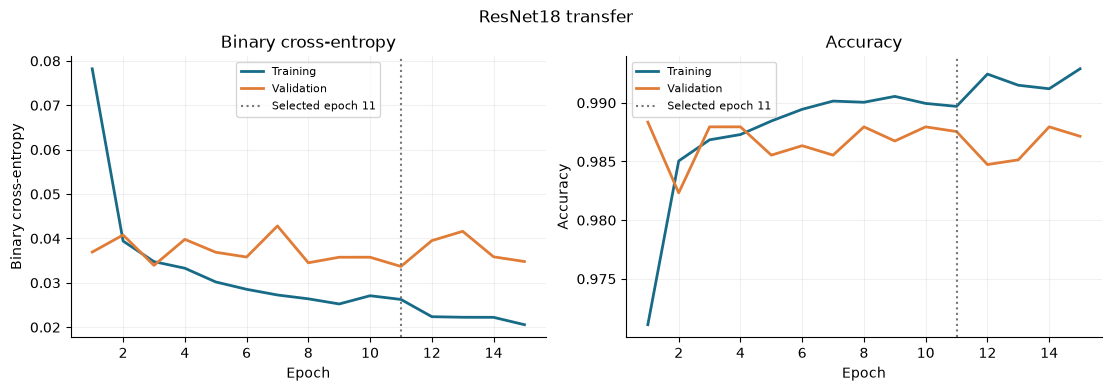

resnet18: 15 epochs; selected checkpoint = epoch 11


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,seconds
12,13,0.02224,0.9915,0.04160,0.98514,0.001,0.36401
13,14,0.02222,0.9912,0.03586,0.98795,0.001,0.45054
14,15,0.02056,0.9929,0.03480,0.98715,0.001,0.38625


In [ ]:
# ResNet18: a different pretrained architecture, with a new head trained at 0.001.
resnet18_history = train_run('resnet18', epochs=15, batch_size=64, workers=WORKERS)
show_history(resnet18_history, 'resnet18')

ResNet18 correctly classifies **2,464 of 2,500 test images (98.56%)**. Epoch 11 has the minimum validation BCE. ResNet18 is selected for custom-image inference because it has the lowest validation BCE among the compared models, before test scores are examined.

<a id="part3"></a>
## Part 3: Residual CNN trained from scratch
For the optional contest, a compact residual CNN is trained using only the course training split. It has channel widths 32, 64, 128 and 256, global average pooling and dropout 0.2. Convolutions use random Kaiming initialization. Residual connections help gradients pass through the deeper network.

No pretrained parameters, cached pretrained features, teacher predictions or external training images are used. Input normalization uses fixed mean and standard deviation 0.5.

The model trains for 60 epochs at 128×128 resolution with batch size 128 and seed 42. Augmentation uses random resized crops, horizontal flips and mild color jitter. AdamW starts at learning rate 0.002 with weight decay 0.0001, followed by cosine decay.

Label smoothing changes training targets from 0/1 to 0.025/0.975. Validation and test BCE use hard labels, so their loss values are not directly comparable with the smoothed training objective. After checkpoint selection, original-image inference is compared with horizontal-flip logit averaging on validation data.

In [ ]:
class ResidualBlock(nn.Module):
    def __init__(self, inputs, outputs, stride=1):
        super().__init__()
        self.main = nn.Sequential(nn.Conv2d(inputs, outputs, 3, stride, 1, bias=False),
                                  nn.BatchNorm2d(outputs), nn.ReLU(),
                                  nn.Conv2d(outputs, outputs, 3, padding=1, bias=False),
                                  nn.BatchNorm2d(outputs))
        self.skip = nn.Identity() if inputs == outputs and stride == 1 else nn.Sequential(
            nn.Conv2d(inputs, outputs, 1, stride, bias=False), nn.BatchNorm2d(outputs))

    def forward(self, x):
        return torch.relu(self.main(x) + self.skip(x))


class ScratchResNet(nn.Module):
    """Compact residual network: random initialization only; no external weights."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(),
            ResidualBlock(32, 32), ResidualBlock(32, 64, 2),
            ResidualBlock(64, 128, 2), ResidualBlock(128, 128),
            ResidualBlock(128, 256, 2), ResidualBlock(256, 256),
            nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(256, 1))
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode='fan_out', nonlinearity='relu')

    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)

Contest parameters, all trainable: 2702753


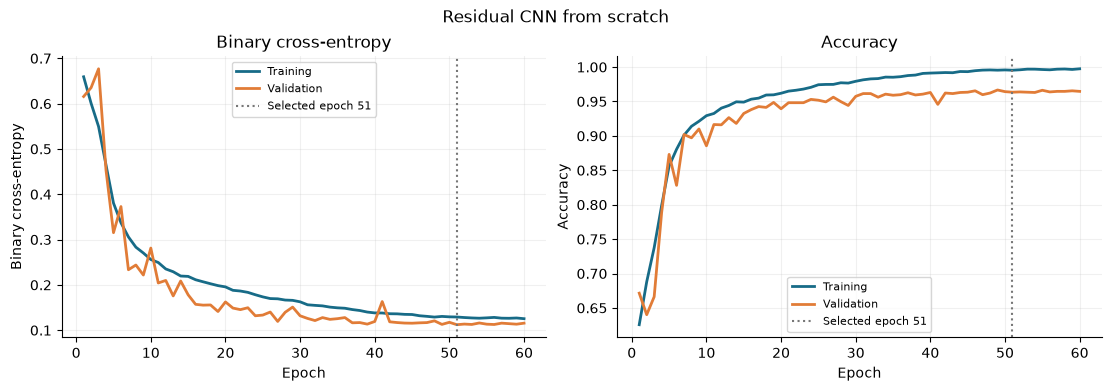

scratch: 60 epochs; selected checkpoint = epoch 51


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,seconds
57,58,0.12636,0.99715,0.11447,0.96466,0.00003,14.83129
58,59,0.12700,0.99650,0.11334,0.96546,0.00003,14.79804
59,60,0.12547,0.99745,0.11559,0.96466,0.00002,14.80743


In [ ]:
contest_model = ScratchResNet()
assert all(p.requires_grad for p in contest_model.parameters())
print('Contest parameters, all trainable:', sum(p.numel() for p in contest_model.parameters()))
del contest_model
scratch_history = train_run('scratch', epochs=60, size=128, batch_size=128, workers=WORKERS)
show_history(scratch_history, 'scratch')

Epoch 51 is selected. Horizontal-flip averaging reduces validation BCE from **0.11219 to 0.10272**, so it is used for final testing. The model correctly classifies **2,408 of 2,500 test images (96.32%)**.

This is the result for the optional no-pretrained-weights contest. The VGG16 and ResNet18 results belong to Part 2 and are excluded from the contest comparison.

<a id="evaluation"></a>
## Final test evaluation
The evaluation routine saves the selected checkpoints and inference settings before opening the test split. It then reports BCE, accuracy, balanced accuracy, dog-class F1, ROC-AUC and approximate 95% Wilson intervals. Per-image predictions are saved when training is repeated.

The following cells evaluate the selected checkpoints and plot the resulting test metrics.

In [ ]:
def load_classifier(checkpoint, device=None):
    device = torch.device(device or ('cuda' if torch.cuda.is_available() else 'cpu'))
    saved = torch.load(checkpoint, map_location='cpu', weights_only=True)
    model = build_model(saved['config']['name'], pretrained=False)
    model.load_state_dict(saved['state_dict'])
    model.to(device).eval()
    return model, saved['config'], device


@torch.inference_mode()
def predict_image(image_path, model, config, device, tta=False):
    """Return the class, both class probabilities and confidence (not calibration)."""
    with Image.open(image_path) as image:
        image = ImageOps.exif_transpose(image).convert('RGB')
        x = preprocessing(config['name'], size=config['image_size'])(image).unsqueeze(0).to(device)
    model.eval()
    with amp(device):
        z = model(x)
        if tta:
            z = (z + model(x.flip(-1))) / 2
    p = z.float().sigmoid().item()
    names = {value: key for key, value in config['class_to_idx'].items()}
    index = int(p >= 0.5)
    return dict(predicted_class=names[index], confidence=p if index else 1 - p,
                probabilities={names[0]: 1 - p, names[1]: p})

In [ ]:
def wilson(correct, total):
    z = 1.959963984540054
    p = correct / total
    d = 1 + z*z / total
    center = (p + z*z / (2*total)) / d
    half = z * math.sqrt(p*(1-p)/total + z*z/(4*total*total)) / d
    return center-half, center+half


def evaluate_all():
    seed_everything(42)
    paths = sorted((ROOT / 'checkpoints').glob('*.pt'))
    selections = {}
    for path in paths:
        saved = torch.load(path, map_location='cpu', weights_only=True)
        selections[path.stem] = dict(name=saved['config']['name'],
                                     best_epoch=saved['best_epoch'],
                                     validation_loss=saved['validation_loss'],
                                     validation_accuracy=saved['validation_accuracy'],
                                     checkpoint_sha256=hashlib.sha256(path.read_bytes()).hexdigest())
    # Test-time augmentation for the contest is selected solely on validation BCE.
    for key, selected in selections.items():
        selected['tta'] = False
        if selected['name'] == 'scratch':
            model, config, device = load_classifier(ROOT / 'checkpoints' / f'{key}.pt')
            val_ds = datasets.ImageFolder(ROOT / 'data/Cats_and_Dogs/val', preprocessing('scratch', size=config['image_size']))
            batches = loader(val_ds, workers=WORKERS)
            plain = evaluate(model, batches, device)
            tta = evaluate(model, batches, device, tta=True)
            selected['validation_plain_loss'] = plain['loss']
            selected['validation_tta_loss'] = tta['loss']
            selected['tta'] = tta['loss'] < plain['loss']
            selected['validation_loss'] = min(plain['loss'], tta['loss'])
            selected['validation_accuracy'] = tta['accuracy'] if selected['tta'] else plain['accuracy']
            del model, batches
            torch.cuda.empty_cache()
    best = min(selections, key=lambda k: selections[k]['validation_loss'])
    locked = dict(best_inference_model=best, selection_rule='lowest validation BCE before test access', models=selections)
    (ROOT / 'results/selection.json').write_text(json.dumps(locked, indent=2))
    rows = []
    for key, selected in selections.items():
        model, config, device = load_classifier(ROOT / 'checkpoints' / f'{key}.pt')
        test_ds = datasets.ImageFolder(ROOT / 'data/Cats_and_Dogs/test', preprocessing(config['name'], size=config['image_size']))
        assert test_ds.class_to_idx == config['class_to_idx']
        result = evaluate(model, loader(test_ds, workers=WORKERS), device, tta=selected['tta'])
        y, p = result['y'].astype(int), result['probabilities']
        pred = (p >= 0.5).astype(int)
        correct = int((pred == y).sum())
        low, high = wilson(correct, len(y))
        row = dict(model=key, pretrained=config['pretrained'], best_epoch=selected['best_epoch'],
                   validation_loss=selected['validation_loss'], test_loss=result['loss'],
                   accuracy=accuracy_score(y,pred), balanced_accuracy=balanced_accuracy_score(y,pred),
                   f1_dog=f1_score(y,pred), roc_auc=roc_auc_score(y,p), correct=correct,
                   test_images=len(y), ci95_low=low, ci95_high=high, tta=selected['tta'])
        rows.append(row)
        dest = ROOT / 'results' / key
        pd.DataFrame(dict(path=[Path(x[0]).relative_to(ROOT / 'data/Cats_and_Dogs').as_posix() for x in test_ds.samples],
                          target=y, probability_dog=p, prediction=pred)).to_csv(dest / 'test_predictions.csv', index=False)
        report = classification_report(y,pred,target_names=test_ds.classes,output_dict=True)
        report['confusion_matrix'] = confusion_matrix(y,pred).tolist()
        (dest / 'test_metrics.json').write_text(json.dumps(dict(**row, classification_report=report), indent=2))
        print(json.dumps(row), flush=True)
        del model
        torch.cuda.empty_cache()
    pd.DataFrame(rows).to_csv(ROOT / 'results/comparison.csv', index=False)
    model, config, device = load_classifier(ROOT / 'checkpoints' / f'{best}.pt')
    custom = []
    for path in sorted((ROOT / 'custom_images').glob('*')):
        if path.suffix.lower() in {'.jpg','.jpeg','.png'}:
            custom.append(dict(image=path.name, **predict_image(path, model, config, device, tta=selections[best]['tta'])))
    (ROOT / 'results/custom_predictions.json').write_text(json.dumps(dict(model=best,predictions=custom), indent=2))

In [ ]:
evaluate_all()
comparison = pd.read_csv(ROOT / 'results/comparison.csv')
selection = json.loads((ROOT / 'results/selection.json').read_text())
metrics = {name: json.loads((ROOT / 'results' / name / 'test_metrics.json').read_text())
           for name in ['cnn', 'vgg16', 'resnet18', 'scratch']}

for name, item in metrics.items():
    cm = np.array(item['classification_report']['confusion_matrix'])
    assert cm.sum() == item['test_images']
    assert abs(cm.trace() / cm.sum() - item['accuracy']) < 1e-10

order = ['cnn', 'vgg16', 'resnet18', 'scratch']
comparison = comparison.set_index('model').loc[order].reset_index()
display(comparison[['model','pretrained','best_epoch','accuracy','test_loss','roc_auc','tta']]
        .style.format({'accuracy':'{:.2%}', 'test_loss':'{:.4f}', 'roc_auc':'{:.4f}'}))
print('Custom-image model selected by validation BCE:', selection['best_inference_model'])
print('Contest entry: residual CNN from scratch.')

,model,pretrained,best_epoch,accuracy,test_loss,roc_auc,tta
0,cnn,False,9,82.16%,0.3842,0.9077,False
1,vgg16,True,1,98.32%,0.0481,0.9984,False
2,resnet18,True,11,98.56%,0.0433,0.9986,False
3,scratch,False,51,96.32%,0.1137,0.9912,True


Custom-image model selected by validation BCE: resnet18
Contest entry: residual CNN from scratch.


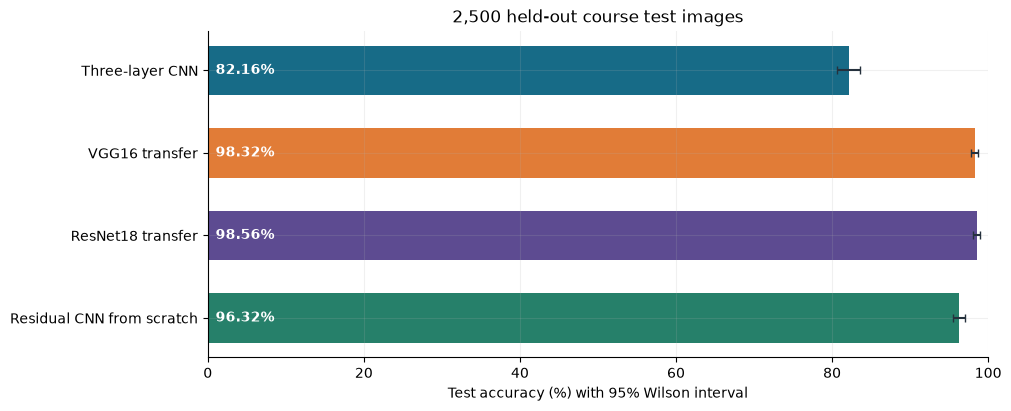

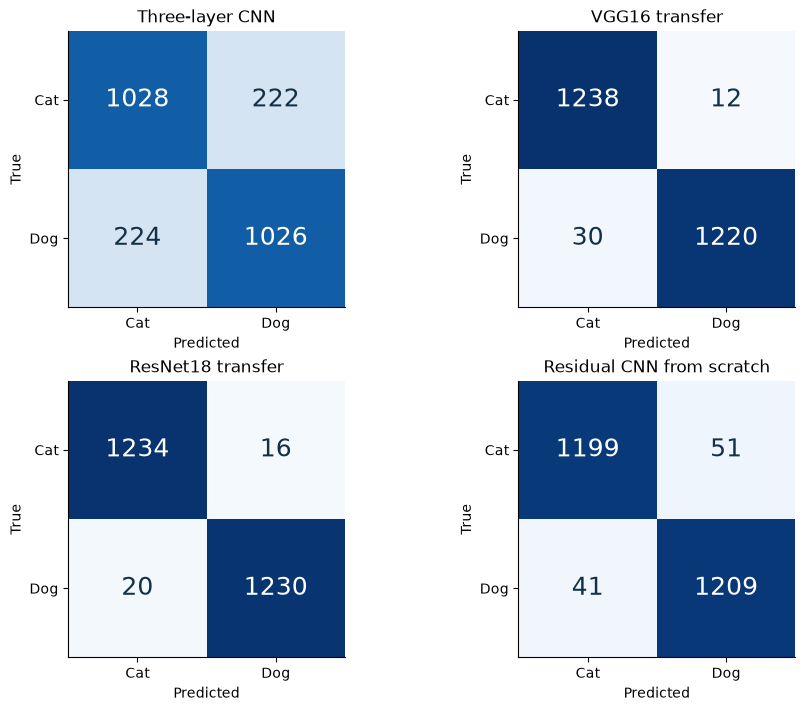

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4), layout='constrained')
x = comparison.accuracy.to_numpy() * 100
y = np.arange(len(comparison))
errors = np.array([x - comparison.ci95_low.to_numpy()*100, comparison.ci95_high.to_numpy()*100 - x])
ax.barh(y, x, color=['#176B87','#E17C37','#5D4B91','#26806A'], height=.6)
ax.errorbar(x, y, xerr=errors, fmt='none', ecolor='#25313D', capsize=3)
for i, value in enumerate(x): ax.text(1, i, f'{value:.2f}%', va='center', color='white', weight='bold')
ax.set(yticks=y, yticklabels=[NAMES[n] for n in comparison.model], xlim=(0,100),
       xlabel='Test accuracy (%) with 95% Wilson interval', title=f'{int(comparison.test_images.iloc[0]):,} held-out course test images')
ax.invert_yaxis()
plt.show()
plt.close(fig)

fig, axes = plt.subplots(2, 2, figsize=(9, 7), layout='constrained')
for ax, name in zip(axes.flat, order):
    cm = np.array(metrics[name]['classification_report']['confusion_matrix'])
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=1250)
    for i in range(2):
        for j in range(2):
            ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=18,
                    color='white' if cm[i,j]>600 else '#123047')
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Cat','Dog'],yticklabels=['Cat','Dog'],
           xlabel='Predicted',ylabel='True',title=NAMES[name])
    ax.grid(False)
plt.show()
plt.close(fig)

### Error analysis

The most confident errors of the validation-selected ResNet18 model. Several photographs contain both species; other examples have small subjects or poor lighting.

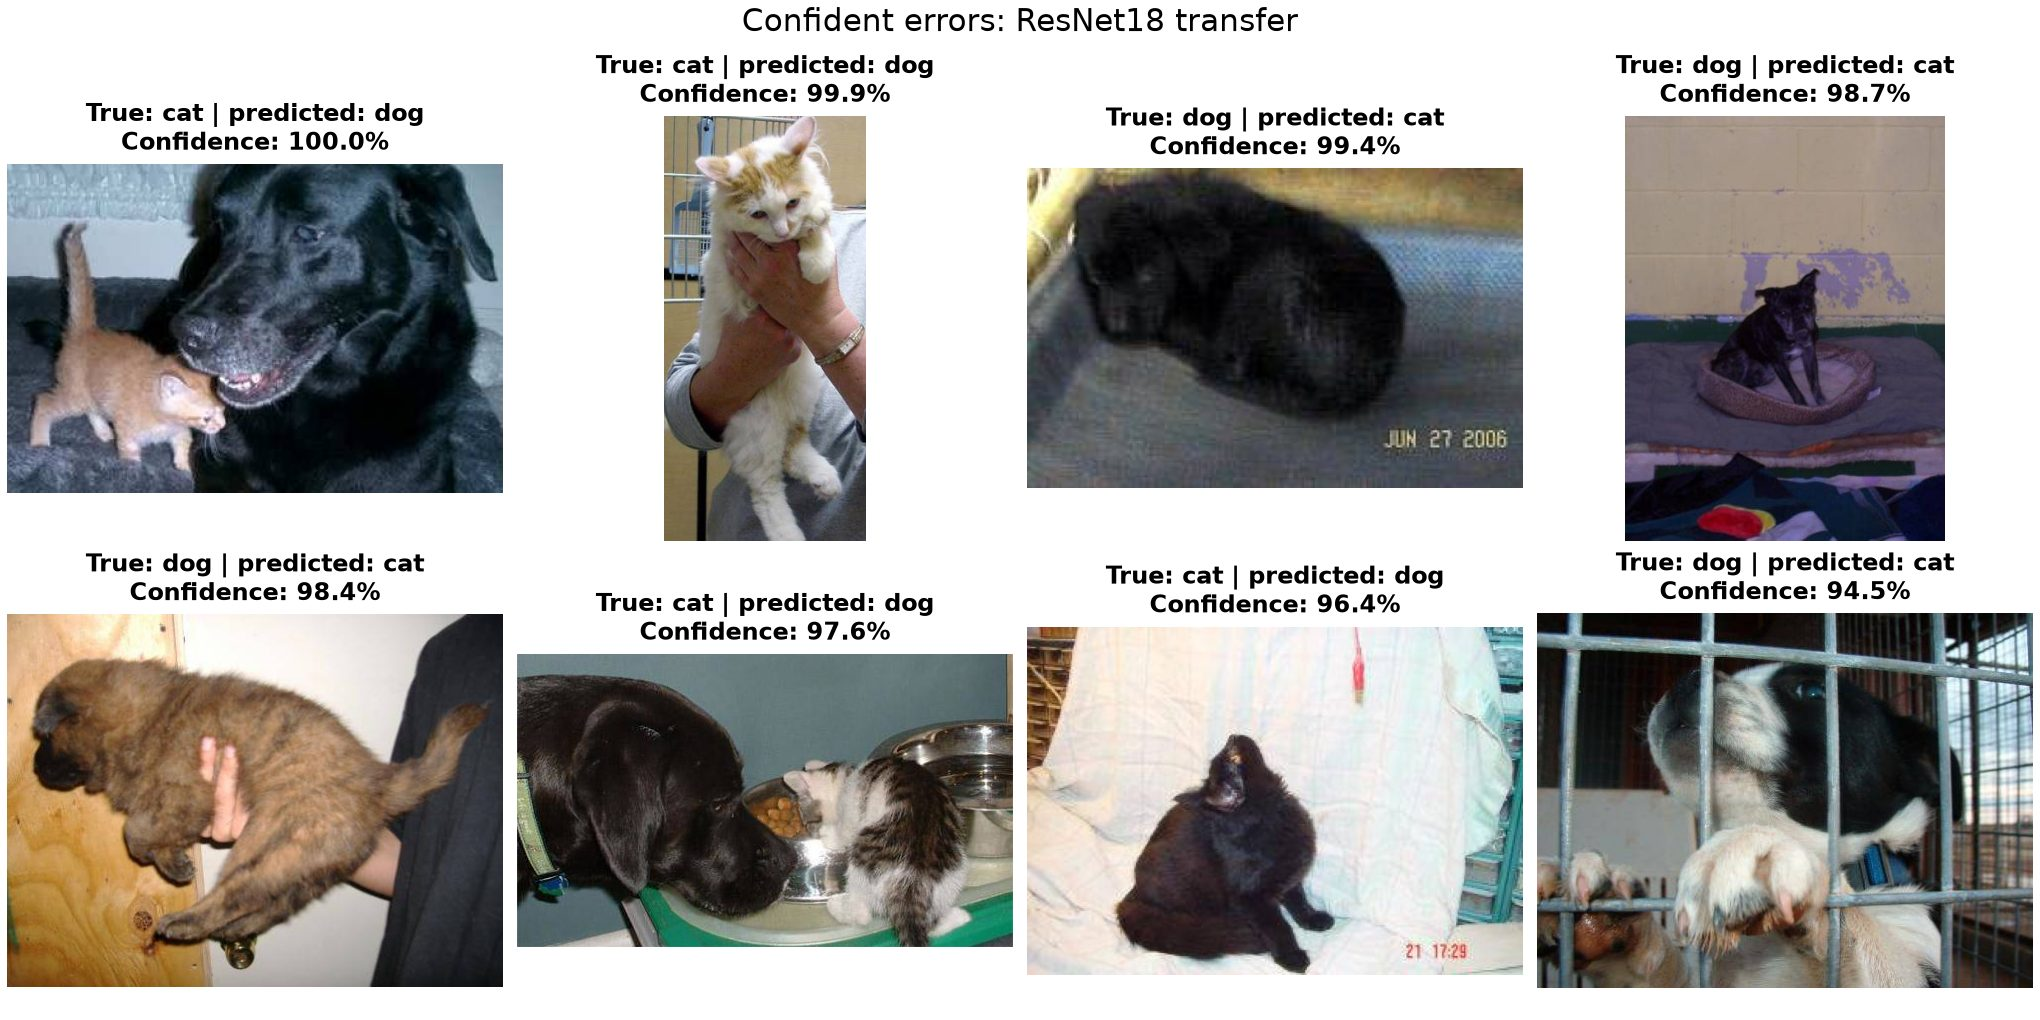

<a id="custom"></a>
## Custom-image inference
The example photograph comes from the [PyTorch Hub repository](https://github.com/pytorch/hub/blob/master/images/dog.jpg). Neither its file hash nor its decoded RGB-pixel hash matches an image in the course archive. Possible overlap with ImageNet is unknown.

`predict_image` handles EXIF orientation, converts the image to RGB, applies the model's preprocessing and returns the class and both probabilities. This single photograph demonstrates inference rather than providing another accuracy estimate.

### Example photograph

Recorded prediction: **dog**, with confidence **88.40%**. This probability is not a calibration guarantee.

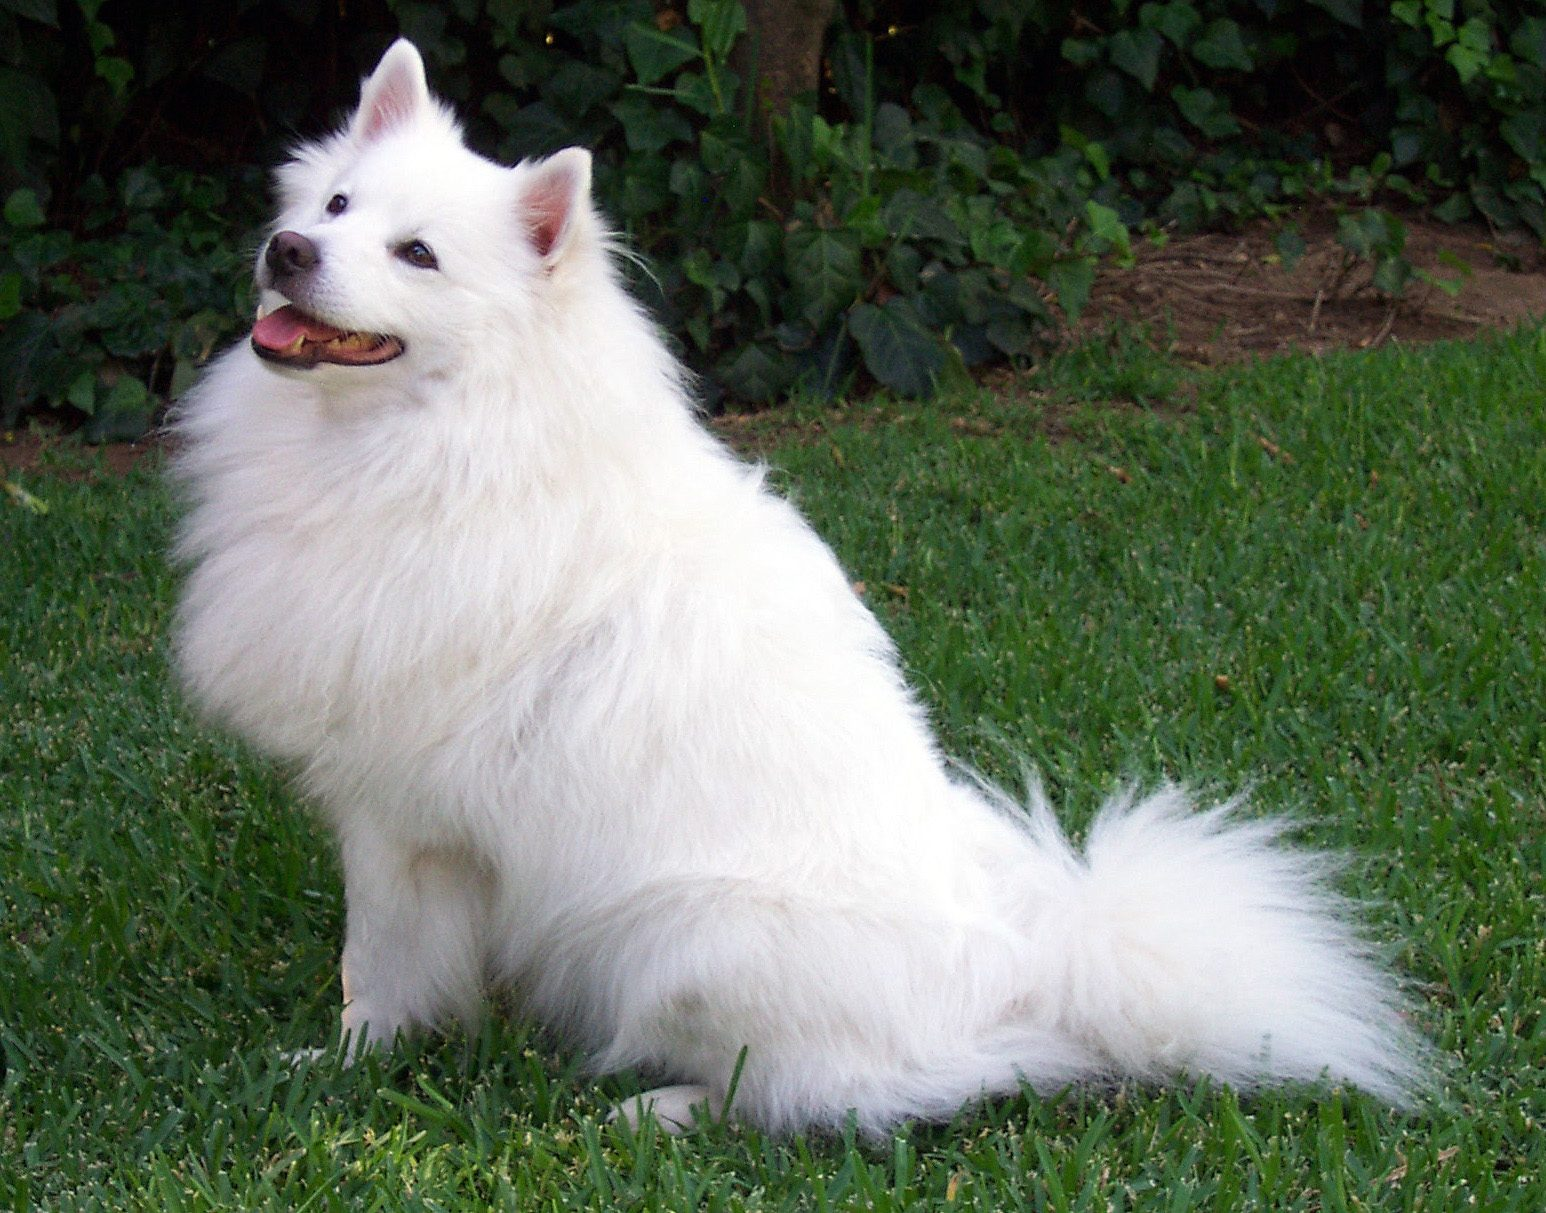

In [ ]:
best = selection['best_inference_model']
checkpoint = ROOT / 'checkpoints' / f'{best}.pt'
if CUSTOM_IMAGE_PATH is None:
    image_path = ROOT / 'custom_images' / 'dog.jpg'
    image_path.parent.mkdir(parents=True, exist_ok=True)
    if not image_path.exists():
        urllib.request.urlretrieve('https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg', image_path)
else:
    image_path = Path(CUSTOM_IMAGE_PATH)
model, config, device = load_classifier(checkpoint)
prediction = predict_image(image_path, model, config, device, tta=selection['models'][best]['tta'])
print(json.dumps(prediction, indent=2))
del model
torch.cuda.empty_cache()

{
  "image": "dog.jpg",
  "predicted_class": "dogs",
  "confidence": 0.8840392827987671,
  "probabilities": {
    "cats": 0.11596071720123291,
    "dogs": 0.8840392827987671
  }
}


## Discussion
The three-layer CNN reaches 82.16% test accuracy. Its validation loss starts to deteriorate while training accuracy continues to rise, indicating overfitting. The residual model trained from scratch reaches 96.32%, although the architecture, augmentation and training budget all differ, so their individual effects cannot be isolated from this comparison.

VGG16 and ResNet18 reach 98.32% and 98.56%. Frozen ImageNet features provide a strong representation for this task. ResNet18 makes six fewer errors than VGG16 on 2,500 images; this small difference does not by itself establish a statistically reliable ranking.

The high-confidence errors include photographs containing both species, where the dataset's single label is ambiguous. Other examples have small subjects or poor lighting. Original test labels were retained, and the errors were inspected only after model selection and evaluation.

There is one training seed per model. The intervals describe approximate test-sample uncertainty rather than variation across training runs. The duplicated test photograph also weakens the independence assumption. Higher-resolution training and ensembles of independently trained scratch models are possible follow-up experiments; neither is claimed as a measured improvement here.

## References
- Task 4 MLT 2026 assignment sheet, supplied course notebook and lecture 7.
- [Course dataset](https://drive.google.com/drive/folders/1KpT0oBIb3aDaBtjf7Hs4WAUPoFEpbsYr).
- [torchvision VGG16](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.vgg16.html).
- [torchvision ResNet18](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html).